In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv(r'C:\Users\Oyenuga Opeyemi\Desktop\Portfolio Projects\Finance of Young Professionals\survey_responses.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Unnamed: 0                  308 non-null    int64 
 1   Timestamp                   308 non-null    object
 2   Age range                   308 non-null    object
 3   state                       308 non-null    object
 4   Occupation/sector           308 non-null    object
 5   employment_type             308 non-null    object
 6   income                      226 non-null    object
 7   Income Frequency            308 non-null    object
 8   monthly_savings             308 non-null    object
 9   pct_saved                   237 non-null    object
 10  emergency_fund              308 non-null    object
 11  emergency_months            213 non-null    object
 12  investment                  308 non-null    object
 13  investment_types            130 non-null    object

In [12]:
df.sample(10)

,Unnamed: 0,Timestamp,Age range,state,Occupation/sector,employment_type,income,Income Frequency,monthly_savings,pct_saved,...,no_investment_reason,Confidence in budgeting,inflation_compound_int,budget_spending,biggest_expense,fin_goal,no_investment_reason_clean,wellness_score,category,lowest_area
187,187,2026/07/15 1:43:58 PM GMT+1,30-34,Lagos,Other,Full-time employee,500k-1m,Regular Weekly/Monthly Salary,Always,11-20%,...,I'm undertaking a project,4,"Yes, both","Yes, consistently",Rent,Business,Other,61,Stable,Investing
94,94,2026/07/12 5:17:42 PM GMT+1,25-29,Lagos,Tech,Self-employed,100k-250k,Irregular/Project-based,Sometimes,1-10%,...,NaN,3,"Yes, both","Yes, consistently",Rent,Business,Other,69,Stable,Saving
33,33,2026/07/11 9:17:10 PM GMT+1,25-29,Ekiti,Other,Self-employed,100k-250k,Regular Weekly/Monthly Salary,Always,21+,...,NaN,4,Neither,Sometimes,Transport,Business,Other,36,Vulnerable,Emergency Fund
217,217,2026/07/12 12:22:22 AM GMT+1,30-34,Lagos,Education,Business owner,<100k,Regular Weekly/Monthly Salary,Sometimes,1-10%,...,NaN,4,One of them,Sometimes,Rent,Debt Freedom,Other,48,At Risk,Emergency Fund
259,259,2026/07/15 7:47:07 AM GMT+1,35+,Ogun,Other,"Unemployed, job-seeking",1m>,Regular Weekly/Monthly Salary,Sometimes,1-10%,...,NaN,1,"Yes, both","Yes, consistently",Rent,Business,Other,60,Stable,Emergency Fund
256,256,2026/07/14 10:10:07 PM GMT+1,35+,Ogun,Tech,Self-employed,1m>,Regular Weekly/Monthly Salary,Sometimes,11-20%,...,Don't earn enough,4,"Yes, both",Sometimes,Other,Debt Freedom,Don't earn enough,37,Vulnerable,Emergency Fund
148,148,2026/07/13 5:46:33 PM GMT+1,18-24,Ondo,Government,Full-time employee,<100k,Regular Weekly/Monthly Salary,Always,1-10%,...,NaN,3,Neither,"Yes, consistently",Other,Business,Other,54,At Risk,Emergency Fund
292,292,2026/07/23 2:29:57 PM GMT+1,30-34,Imo,Government,Full-time employee,1m>,Regular Weekly/Monthly Salary,Always,1-10%,...,Haven't gotten to it,5,One of them,Sometimes,Family Support,Home Ownership,Haven't gotten to it,42,At Risk,Investing
189,189,2026/07/15 4:39:53 PM GMT+1,18-24,Benue,Other,Self-employed,<100k,Irregular/Project-based,Always,1-10%,...,Don't earn enough,5,Neither,"Yes, consistently",Food,Business,Don't earn enough,38,Vulnerable,Emergency Fund
290,290,2026/07/21 5:07:49 PM GMT+1,18-24,Lagos,Healthcare,Business owner,1m>,Regular Weekly/Monthly Salary,Sometimes,21+,...,NaN,5,"Yes, both","Yes, consistently",Rent,Business,Other,55,At Risk,Emergency Fund


In [9]:
df['income'] = df['income'].fillna('1m>')

In [13]:
df.head(1)

,Unnamed: 0,Timestamp,Age range,state,Occupation/sector,employment_type,income,Income Frequency,monthly_savings,pct_saved,...,no_investment_reason,Confidence in budgeting,inflation_compound_int,budget_spending,biggest_expense,fin_goal,no_investment_reason_clean,wellness_score,category,lowest_area
0,0,2026/07/11 2:19:43 PM GMT+1,18-24,Lagos,Other,Self-employed,100k-250k,Irregular/Project-based,Never,21+,...,Don't earn enough,4,One of them,Sometimes,Food,Home Ownership,Don't earn enough,30,Vulnerable,Saving


In [11]:
df['pct_saved'] = df['pct_saved'].fillna('21+')

In [14]:
rename_map = {
    "Unnamed": "response_id",
    "Timestamp": "timestamp",
    "Age range": "age_range",
    "state": "state",
    "Occupation/sector": "occupation_sector",
    "employment_type": "employment_type",
    "income": "income",
    "Income Frequency": "income_frequency",
    "monthly_savings": "monthly_savings",
    "pct_saved": "pct_saved",
    "emergency_fund": "emergency_fund",
    "emergency_months": "emergency_months",
    "investment": "investment",
    "investment_types": "investment_types",
    "no_investment_reason": "no_investment_reason",
    "Confidence in budgeting": "confidence_budgeting",
    "inflation_compound_int": "inflation_compound_int",
    "budget_spending": "budget_spending",
    "biggest_expense": "biggest_expense",
    "fin_goal": "fin_goal",
    "no_investment_reason_clean": "no_investment_reason_clean", 
    "wellness_score": "wellness_score",
    "category": "category",
    "lowest_area": "lowest_area",
}

df = df.rename(columns=rename_map)
df.columns = df.columns.str.strip()

print("Columns after rename:", df.columns.tolist())
print(df.shape)
df.head()

Columns after rename: ['Unnamed: 0', 'timestamp', 'age_range', 'state', 'occupation_sector', 'employment_type', 'income', 'income_frequency', 'monthly_savings', 'pct_saved', 'emergency_fund', 'emergency_months', 'investment', 'investment_types', 'no_investment_reason', 'confidence_budgeting', 'inflation_compound_int', 'budget_spending', 'biggest_expense', 'fin_goal', 'no_investment_reason_clean', 'wellness_score', 'category', 'lowest_area']
(308, 24)


,Unnamed: 0,timestamp,age_range,state,occupation_sector,employment_type,income,income_frequency,monthly_savings,pct_saved,...,no_investment_reason,confidence_budgeting,inflation_compound_int,budget_spending,biggest_expense,fin_goal,no_investment_reason_clean,wellness_score,category,lowest_area
0,0,2026/07/11 2:19:43 PM GMT+1,18-24,Lagos,Other,Self-employed,100k-250k,Irregular/Project-based,Never,21+,...,Don't earn enough,4,One of them,Sometimes,Food,Home Ownership,Don't earn enough,30,Vulnerable,Saving
1,1,2026/07/11 2:20:26 PM GMT+1,25-29,Ogun,Education,"Unemployed, job-seeking",250k-500k,Irregular/Project-based,Sometimes,11-20%,...,Don't earn enough,4,"Yes, both",Sometimes,Food,Travel,Don't earn enough,37,Vulnerable,Emergency Fund
2,2,2026/07/11 2:36:01 PM GMT+1,35+,Oyo,Education,Full-time employee,100k-250k,Regular Weekly/Monthly Salary,Always,11-20%,...,NaN,2,One of them,No,Data,Travel,Other,44,At Risk,Emergency Fund
3,3,2026/07/11 2:48:10 PM GMT+1,18-24,Imo,Other,Self-employed,100k-250k,Regular Weekly/Monthly Salary,Always,1-10%,...,NaN,4,"Yes, both","Yes, consistently",Food,Business,Other,73,Stable,Saving
4,4,2026/07/11 3:38:06 PM GMT+1,18-24,Ogun,Tech,Full-time employee,100k-250k,Regular Weekly/Monthly Salary,Always,21+,...,Don't earn enough,4,"Yes, both","Yes, consistently",Food,Business,Don't earn enough,43,At Risk,Saving


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Unnamed: 0                  308 non-null    int64 
 1   timestamp                   308 non-null    object
 2   age_range                   308 non-null    object
 3   state                       308 non-null    object
 4   occupation_sector           308 non-null    object
 5   employment_type             308 non-null    object
 6   income                      308 non-null    object
 7   income_frequency            308 non-null    object
 8   monthly_savings             308 non-null    object
 9   pct_saved                   308 non-null    object
 10  emergency_fund              308 non-null    object
 11  emergency_months            213 non-null    object
 12  investment                  308 non-null    object
 13  investment_types            130 non-null    object

In [16]:
df.isnull().sum().sort_values(ascending=False)

investment_types              178
no_investment_reason          130
emergency_months               95
inflation_compound_int          1
Unnamed: 0                      0
category                        0
wellness_score                  0
no_investment_reason_clean      0
fin_goal                        0
biggest_expense                 0
budget_spending                 0
confidence_budgeting            0
investment                      0
timestamp                       0
emergency_fund                  0
pct_saved                       0
monthly_savings                 0
income_frequency                0
income                          0
employment_type                 0
occupation_sector               0
state                           0
age_range                       0
lowest_area                     0
dtype: int64

In [17]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,308.0,NaN,NaN,NaN,153.5,89.056162,0.0,76.75,153.5,230.25,307.0
timestamp,308,208,2026/07/17 8:28:33 AM GMT+1,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_range,308,4,18-24,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,308,19,Lagos,117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation_sector,308,7,Other,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,308,5,Full-time employee,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income,308,5,<100k,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_frequency,308,3,Regular Weekly/Monthly Salary,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_savings,308,4,Sometimes,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pct_saved,308,4,1-10%,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
categorical_cols = [
    "age_range", "state", "occupation_sector", "employment_type",
    "income", "income_frequency", "emergency_fund", "investment",
    "fin_goal", "category"
]

In [21]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(normalize=True).round(3) * 100)


--- age_range ---
age_range
18-24    40.3
25-29    37.3
30-34    14.6
35+       7.8
Name: proportion, dtype: float64

--- state ---
state
Lagos          38.0
Ogun           21.8
Oyo             8.4
Ondo            5.5
Osun            3.9
FCT (Abuja)     3.6
Edo             3.6
Delta           3.2
Kwara           1.9
Akwa Ibom       1.9
Rivers          1.6
Ekiti           1.3
Anambra         1.3
Imo             1.3
Kaduna          0.6
Enugu           0.6
Abia            0.6
Kogi            0.3
Benue           0.3
Name: proportion, dtype: float64

--- occupation_sector ---
occupation_sector
Other             40.3
Tech              24.7
Education         10.7
Fashion/Retail     8.4
Healthcare         6.5
Banking            6.2
Government         3.2
Name: proportion, dtype: float64

--- employment_type ---
employment_type
Full-time employee         35.4
Freelancer                 21.1
Self-employed              17.5
Unemployed, job-seeking    13.3
Business owner             12.7
Name: pr

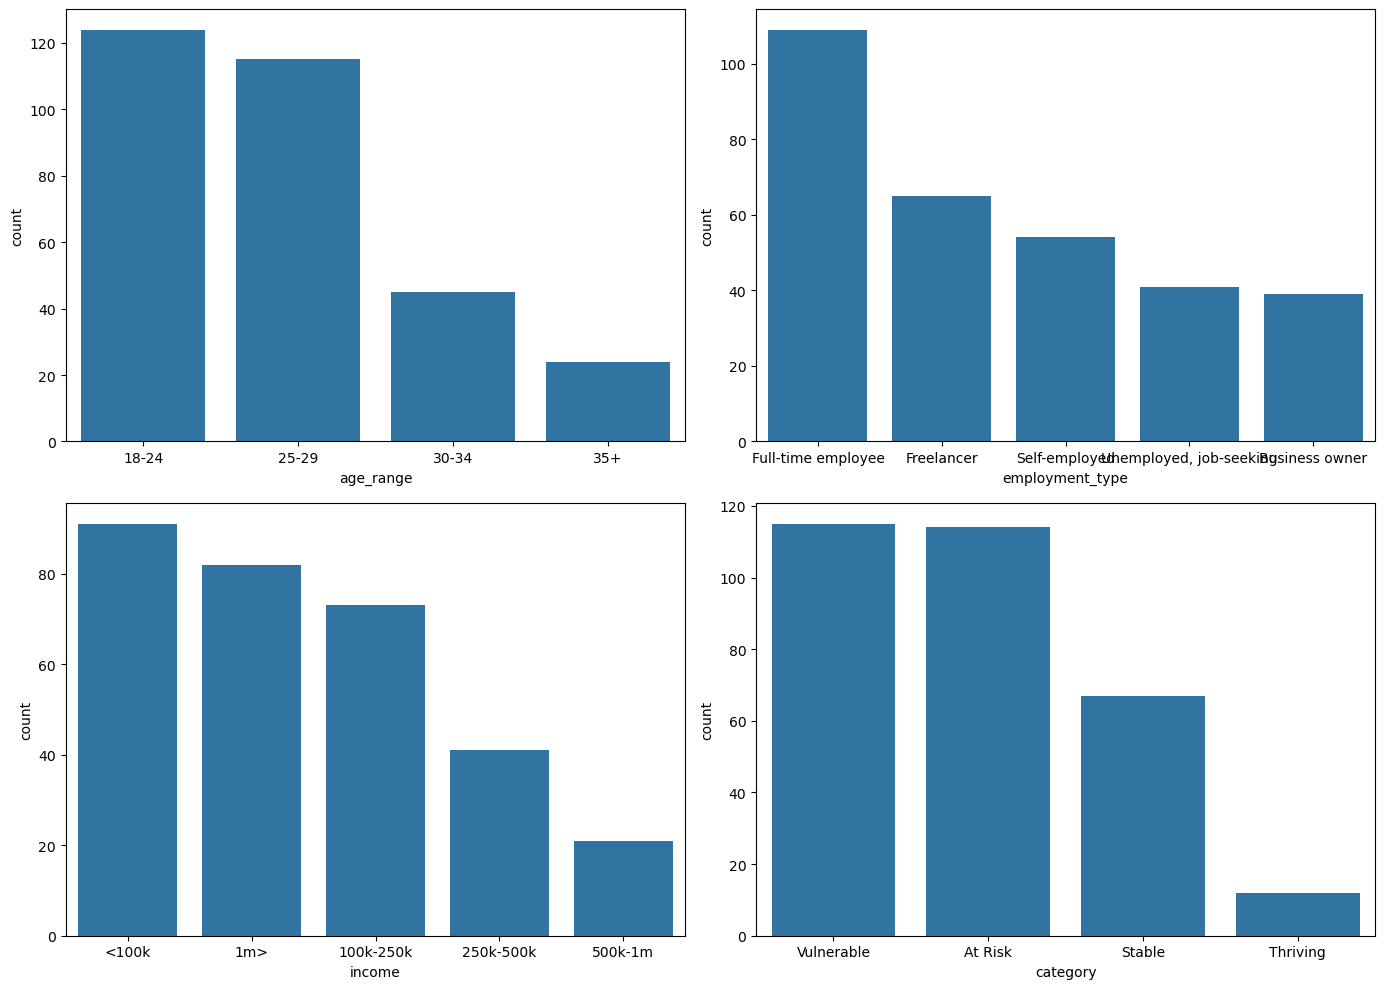

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=df, x="age_range", ax=axes[0, 0], order=df["age_range"].value_counts().index)
sns.countplot(data=df, x="employment_type", ax=axes[0, 1], order=df["employment_type"].value_counts().index)
sns.countplot(data=df, x="income", ax=axes[1, 0], order=df["income"].value_counts().index)
sns.countplot(data=df, x="category", ax=axes[1, 1], order=["Vulnerable", "At Risk", "Stable", "Thriving"])
plt.tight_layout()
plt.savefig("demographics_overview.png", dpi=150)
plt.show()

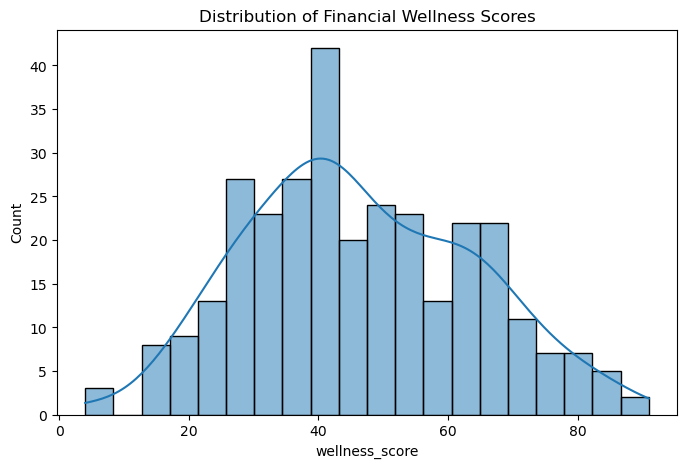

In [24]:
plt.figure(figsize=(8, 5))
sns.histplot(df["wellness_score"], bins=20, kde=True)
plt.title("Distribution of Financial Wellness Scores")
plt.savefig("wellness_score_distribution.png", dpi=150)
plt.show()

In [26]:
income_order = ["<100k", "100k-250k", "250k-500k", "500k-1m", "1m>"]

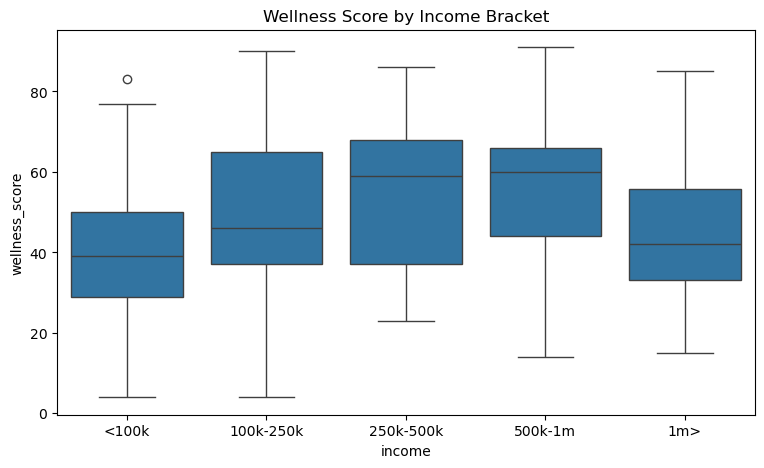

In [27]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="income", y="wellness_score", order=income_order)
plt.title("Wellness Score by Income Bracket")
plt.savefig("wellness_by_income.png", dpi=150)
plt.show()

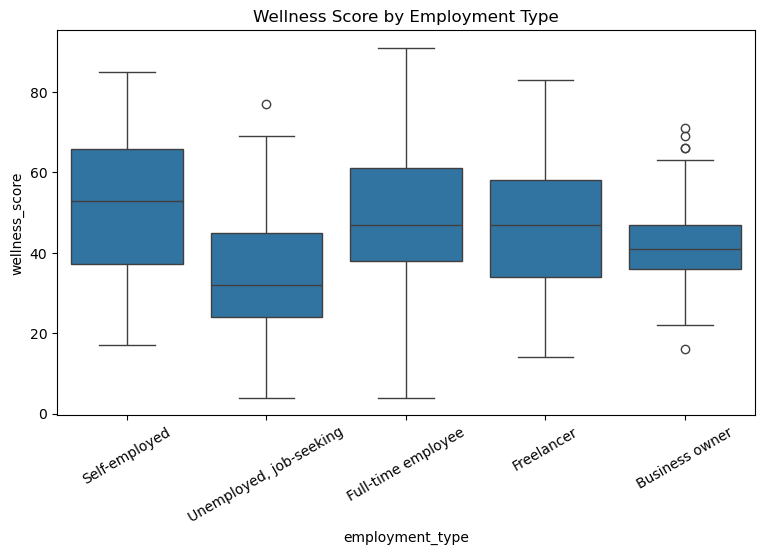

In [28]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="employment_type", y="wellness_score")
plt.title("Wellness Score by Employment Type")
plt.xticks(rotation=30)
plt.savefig("wellness_by_employment.png", dpi=150)
plt.show()

In [29]:
pd.crosstab(df["income"], df["emergency_fund"], normalize="index").round(3) * 100

emergency_fund,No,Yes
income,,
100k-250k,38.4,61.6
1m>,39.0,61.0
250k-500k,31.7,68.3
500k-1m,19.0,81.0
<100k,57.1,42.9


In [30]:
pd.crosstab(df["age_range"], df["investment"], normalize="index").round(3) * 100

investment,No,Yes
age_range,,
18-24,60.5,39.5
25-29,57.4,42.6
30-34,51.1,48.9
35+,58.3,41.7


In [31]:
print(df["lowest_area"].value_counts(normalize=True).round(3) * 100)

lowest_area
Emergency Fund        48.1
Saving                25.3
Investing             22.4
Budgeting              3.6
Financial Literacy     0.6
Name: proportion, dtype: float64


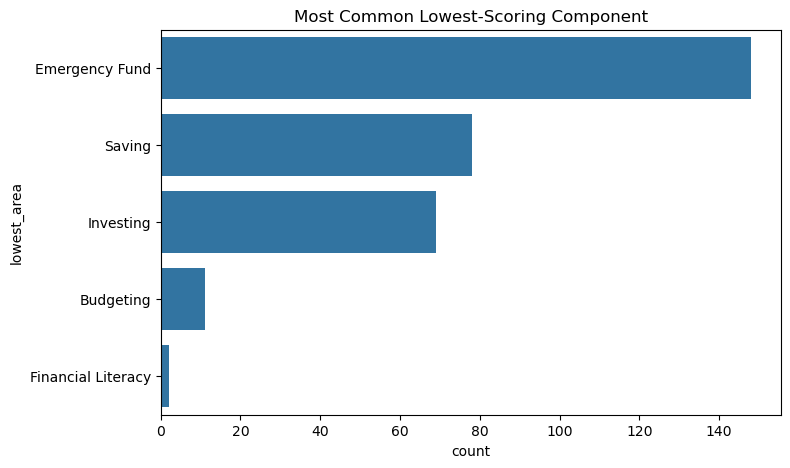

In [32]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, y="lowest_area", order=df["lowest_area"].value_counts().index)
plt.title("Most Common Lowest-Scoring Component")
plt.savefig("lowest_area_distribution.png", dpi=150)
plt.show()

In [33]:
region_map = {
    "Lagos": "South West", "Ogun": "South West", "Oyo": "South West", "Ondo": "South West", "Osun": "South West", "Ekiti": "South West",
    "FCT (Abuja)": "North Central", "Kwara": "North Central", "Kogi": "North Central", "Benue": "North Central",
    "Kaduna": "North West",
    "Rivers": "South South",  "Edo": "South South", "Delta": "South South", "Akwa Ibom" : "South South",
    "Enugu": "South East", "Anambra": "South East", "Imo": "South East", "Abia": "South East"
}

In [34]:
df["region"] = df["state"].map(region_map)

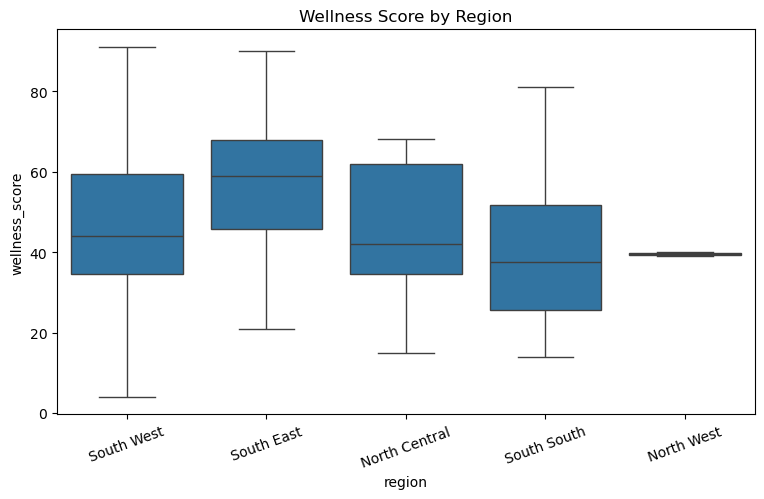

In [35]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="region", y="wellness_score")
plt.title("Wellness Score by Region")
plt.xticks(rotation=20)
plt.savefig("wellness_by_region.png", dpi=150)
plt.show()

In [36]:
# ANOVA: wellness_score across income brackets
groups = [df.loc[df["income"] == g, "wellness_score"].dropna() for g in df["income"].unique()]
f_stat, p_val = stats.f_oneway(*groups)
print(f"ANOVA (income vs wellness_score): F={f_stat:.2f}, p={p_val:.4f}")

ANOVA (income vs wellness_score): F=8.41, p=0.0000


In [37]:
# ANOVA: wellness_score across employment types
groups_emp = [df.loc[df["employment_type"] == g, "wellness_score"].dropna() for g in df["employment_type"].unique()]
f_stat_emp, p_val_emp = stats.f_oneway(*groups_emp)
print(f"ANOVA (employment_type vs wellness_score): F={f_stat_emp:.2f}, p={p_val_emp:.4f}")

ANOVA (employment_type vs wellness_score): F=6.11, p=0.0001


In [39]:
df['pct_saved'] = df['pct_saved'].str.replace('21+', '>21%', regex=False)

In [42]:
print(df[numeric_cols].dtypes)

pct_saved               object
emergency_months        object
confidence_budgeting     int64
wellness_score           int64
dtype: object


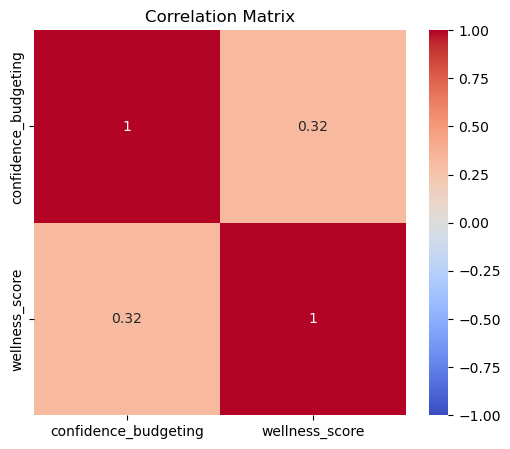

In [43]:
# Correlation matrix (numeric fields)
numeric_cols = ["confidence_budgeting", "wellness_score"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.savefig("correlation_matrix.png", dpi=150)
plt.show()

In [44]:
findings = []

In [45]:
avg_score = df["wellness_score"].mean()
findings.append(f"Average wellness score: {avg_score:.1f}")

In [46]:
pct_vulnerable = (df["category"] == "Vulnerable").mean() * 100
findings.append(f"% respondents classified Vulnerable: {pct_vulnerable:.1f}%")

In [47]:
top_lowest_area = df["lowest_area"].value_counts().idxmax()
findings.append(f"Most common weakest component: {top_lowest_area}")

In [48]:
for f in findings:
    print(f)

Average wellness score: 46.3
% respondents classified Vulnerable: 37.3%
Most common weakest component: Emergency Fund
